In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from scipy.stats import ttest_1samp, ttest_ind, f_oneway
from scipy.stats import shapiro, pearsonr, t

from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

import os
import warnings

warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [6]:
import os
import pandas as pd

sales_path = "/content/sales_data.csv"
churn_path = "/content/customer_churn.csv"

if os.path.exists(sales_path):
    sales_df = pd.read_csv(sales_path)
    print("Sales dataset loaded successfully!")
    print("Sales dataset shape:", sales_df.shape)
else:
    print("sales_data.csv not found!")

if os.path.exists(churn_path):
    churn_df = pd.read_csv(churn_path)
    print("\nCustomer churn dataset loaded successfully!")
    print("Customer churn dataset shape:", churn_df.shape)
else:
    print("customer_churn.csv not found!")

Sales dataset loaded successfully!
Sales dataset shape: (100, 7)

Customer churn dataset loaded successfully!
Customer churn dataset shape: (500, 9)


In [7]:
print("SALES DATASET")
print("=" * 50)

print("\nColumn Names:")
print(sales_df.columns.tolist())

print("\nDataset Information:")
sales_df.info()

print("\nFirst 5 Rows:")
display(sales_df.head())

print("\nMissing Values:")
print(sales_df.isnull().sum())

SALES DATASET

Column Names:
['Date', 'Product', 'Quantity', 'Price', 'Customer_ID', 'Region', 'Total_Sales']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Date         100 non-null    object
 1   Product      100 non-null    object
 2   Quantity     100 non-null    int64 
 3   Price        100 non-null    int64 
 4   Customer_ID  100 non-null    object
 5   Region       100 non-null    object
 6   Total_Sales  100 non-null    int64 
dtypes: int64(3), object(4)
memory usage: 5.6+ KB

First 5 Rows:


,Date,Product,Quantity,Price,Customer_ID,Region,Total_Sales
0,2024-01-01,Phone,7,37300,CUST001,East,261100
1,2024-01-02,Headphones,4,15406,CUST002,North,61624
2,2024-01-03,Phone,2,21746,CUST003,West,43492
3,2024-01-04,Headphones,1,30895,CUST004,East,30895
4,2024-01-05,Laptop,8,39835,CUST005,North,318680



Missing Values:
Date           0
Product        0
Quantity       0
Price          0
Customer_ID    0
Region         0
Total_Sales    0
dtype: int64


In [8]:
print("CUSTOMER CHURN DATASET")
print("=" * 50)

print("\nColumn Names:")
print(churn_df.columns.tolist())

print("\nDataset Information:")
churn_df.info()

print("\nFirst 5 Rows:")
display(churn_df.head())

print("\nMissing Values:")
print(churn_df.isnull().sum())

CUSTOMER CHURN DATASET

Column Names:
['CustomerID', 'Tenure', 'MonthlyCharges', 'TotalCharges', 'Contract', 'PaymentMethod', 'PaperlessBilling', 'SeniorCitizen', 'Churn']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   CustomerID        500 non-null    object
 1   Tenure            500 non-null    int64 
 2   MonthlyCharges    500 non-null    int64 
 3   TotalCharges      500 non-null    int64 
 4   Contract          500 non-null    object
 5   PaymentMethod     500 non-null    object
 6   PaperlessBilling  500 non-null    object
 7   SeniorCitizen     500 non-null    int64 
 8   Churn             500 non-null    int64 
dtypes: int64(5), object(4)
memory usage: 35.3+ KB

First 5 Rows:


,CustomerID,Tenure,MonthlyCharges,TotalCharges,Contract,PaymentMethod,PaperlessBilling,SeniorCitizen,Churn
0,C00001,6,64,1540,One year,Credit Card,No,1,0
1,C00002,21,113,1753,Month-to-month,Electronic Check,Yes,1,0
2,C00003,27,31,1455,Two year,Credit Card,No,1,0
3,C00004,53,29,7150,Month-to-month,Electronic Check,No,1,0
4,C00005,16,185,1023,One year,Electronic Check,No,1,0



Missing Values:
CustomerID          0
Tenure              0
MonthlyCharges      0
TotalCharges        0
Contract            0
PaymentMethod       0
PaperlessBilling    0
SeniorCitizen       0
Churn               0
dtype: int64


In [9]:
# Descriptive Statistics
print(sales_df.describe())

print("\nMean:\n", sales_df.mean(numeric_only=True))
print("\nMedian:\n", sales_df.median(numeric_only=True))
print("\nMode:\n", sales_df.mode().iloc[0])
print("\nStandard Deviation:\n", sales_df.std(numeric_only=True))

         Quantity         Price    Total_Sales
count  100.000000    100.000000     100.000000
mean     4.780000  25808.510000  123650.480000
std      2.588163  13917.630242  100161.085275
min      1.000000   1308.000000    6540.000000
25%      2.750000  14965.250000   39517.500000
50%      5.000000  24192.000000   97955.500000
75%      7.000000  38682.250000  175792.500000
max      9.000000  49930.000000  373932.000000

Mean:
 Quantity            4.78
Price           25808.51
Total_Sales    123650.48
dtype: float64

Median:
 Quantity           5.0
Price          24192.0
Total_Sales    97955.5
dtype: float64

Mode:
 Date           2024-01-01
Product            Tablet
Quantity              4.0
Price                1308
Customer_ID       CUST001
Region              North
Total_Sales          6540
Name: 0, dtype: object

Standard Deviation:
 Quantity            2.588163
Price           13917.630242
Total_Sales    100161.085275
dtype: float64


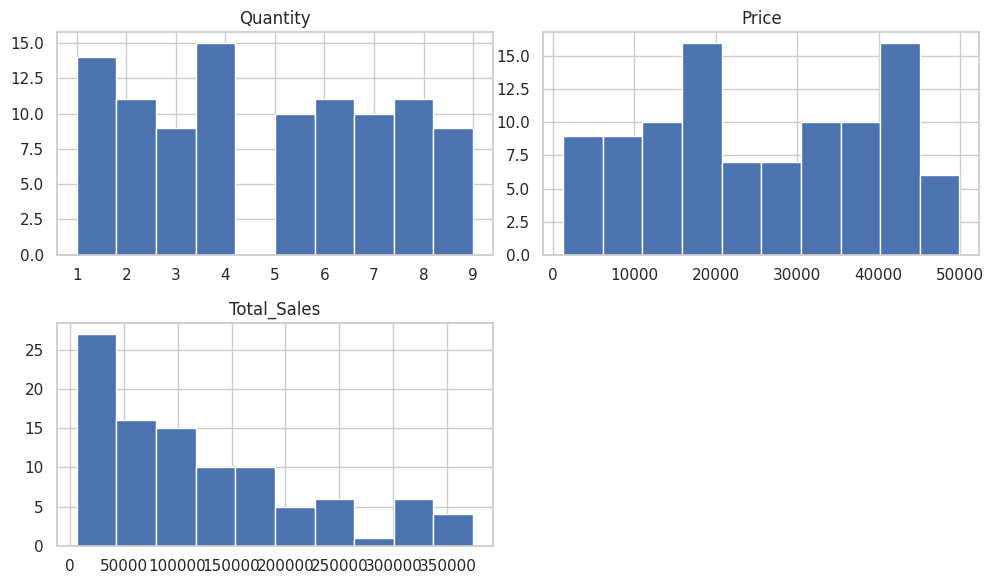

In [10]:
import matplotlib.pyplot as plt

sales_df.hist(figsize=(10, 6))
plt.tight_layout()
plt.show()

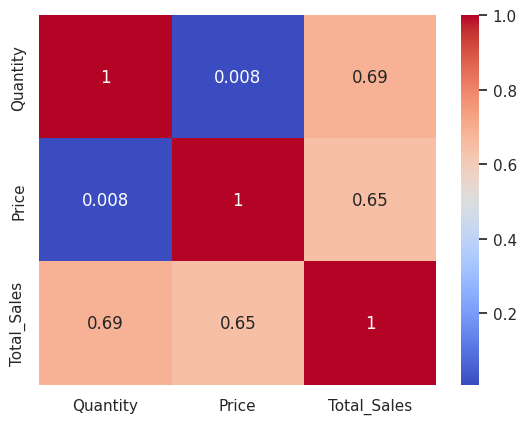

In [11]:
import seaborn as sns

sns.heatmap(
    sales_df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm"
)
plt.show()

In [12]:
print(sales_df.columns.tolist())

['Date', 'Product', 'Quantity', 'Price', 'Customer_ID', 'Region', 'Total_Sales']


In [13]:
from scipy.stats import ttest_1samp, shapiro, pearsonr

# Select numeric column
col = sales_df.select_dtypes(include="number").columns[0]
data = sales_df[col].dropna()

# Test 1: One-sample t-test
print("T-Test:", ttest_1samp(data, popmean=data.mean()))

# Test 2: Normality test
print("Normality Test:", shapiro(data))

# Test 3: Correlation between first two numeric columns
numeric = sales_df.select_dtypes(include="number").dropna()

if numeric.shape[1] >= 2:
    print("Correlation:", pearsonr(numeric.iloc[:, 0], numeric.iloc[:, 1]))

T-Test: TtestResult(statistic=np.float64(0.0), pvalue=np.float64(1.0), df=np.int64(99))
Normality Test: ShapiroResult(statistic=np.float64(0.9304459212578251), pvalue=np.float64(5.2757746484393684e-05))
Correlation: PearsonRResult(statistic=np.float64(0.008014446139936399), pvalue=np.float64(0.9369227735514832))


In [14]:
import scipy.stats as stats
import numpy as np

data = sales_df.select_dtypes(include="number").iloc[:, 0].dropna()

mean = np.mean(data)
se = stats.sem(data)
ci = stats.t.interval(0.95, len(data)-1, loc=mean, scale=se)

print("Mean:", round(mean, 2))
print("95% Confidence Interval:", ci)
print("Margin of Error:", round(ci[1] - mean, 2))

Mean: 4.78
95% Confidence Interval: (np.float64(4.266452381357786), np.float64(5.293547618642214))
Margin of Error: 0.51


In [15]:
# Day 6: Linear Regression

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
import matplotlib.pyplot as plt

# Select numeric data
data = sales_df.select_dtypes(include="number").dropna()

# First column as input and second as output
X = data.iloc[:, [0]]
y = data.iloc[:, 1]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train the model
model = LinearRegression()
model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)

# Check model performance
print("R2 Score:", round(r2_score(y_test, y_pred), 2))
print("Model training completed!")

R2 Score: -0.01
Model training completed!


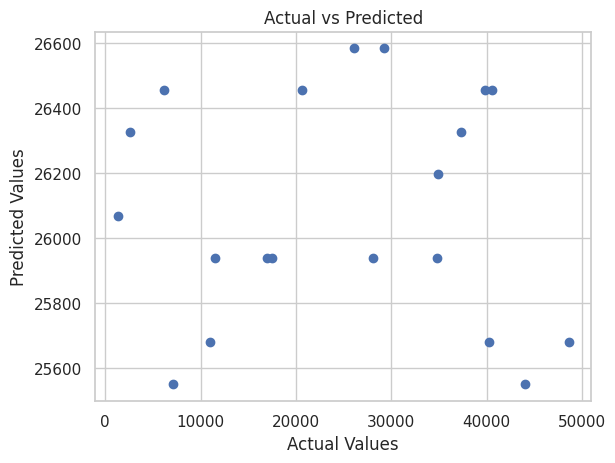

In [16]:
plt.scatter(y_test, y_pred)
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Actual vs Predicted")
plt.show()

In [17]:
# Day 7: Business Insights

print("BUSINESS ANALYSIS REPORT")
print("-" * 30)

print("1. Total Records:", len(sales_df))

numeric_data = sales_df.select_dtypes(include="number")

for col in numeric_data.columns:
    print(f"\n2. {col}")
    print("   Average:", round(sales_df[col].mean(), 2))
    print("   Highest:", sales_df[col].max())
    print("   Lowest:", sales_df[col].min())

print("\nRECOMMENDATIONS:")
print("1. Analyze the factors affecting sales.")
print("2. Focus on improving low-performing areas.")
print("3. Use statistical results to support business decisions.")

BUSINESS ANALYSIS REPORT
------------------------------
1. Total Records: 100

2. Quantity
   Average: 4.78
   Highest: 9
   Lowest: 1

2. Price
   Average: 25808.51
   Highest: 49930
   Lowest: 1308

2. Total_Sales
   Average: 123650.48
   Highest: 373932
   Lowest: 6540

RECOMMENDATIONS:
1. Analyze the factors affecting sales.
2. Focus on improving low-performing areas.
3. Use statistical results to support business decisions.


In [18]:
with open("business_insights.txt", "w") as file:
    file.write("Business Analysis Report\n")
    file.write("-" * 30 + "\n")

    for col in numeric_data.columns:
        file.write(f"\n{col}\n")
        file.write(f"Average: {sales_df[col].mean():.2f}\n")
        file.write(f"Highest: {sales_df[col].max()}\n")
        file.write(f"Lowest: {sales_df[col].min()}\n")

    file.write("\nRecommendations:\n")
    file.write("1. Analyze factors affecting sales.\n")
    file.write("2. Improve low-performing areas.\n")
    file.write("3. Use statistical results for decisions.\n")

print("Report saved successfully!")

Report saved successfully!


In [19]:
import os

# Create project folder
os.makedirs("statistical_analysis", exist_ok=True)

# Save analysis results
sales_df.to_csv("statistical_analysis/business_data.csv", index=False)

# Save requirements
with open("statistical_analysis/requirements.txt", "w") as f:
    f.write("pandas\nnumpy\nmatplotlib\nseaborn\nscipy\nscikit-learn\n")

print("Project files created successfully!")
print(os.listdir("statistical_analysis"))

Project files created successfully!
['business_data.csv', 'requirements.txt']


In [22]:
sales_df.to_csv("business_data.csv", index=False)
print("business_data.csv saved!")

business_data.csv saved!


In [23]:
with open("requirements.txt", "w") as f:
    f.write("pandas\nnumpy\nmatplotlib\nseaborn\nscipy\nscikit-learn\n")
print("requirements.txt saved!")

requirements.txt saved!


In [24]:
from scipy.stats import ttest_1samp

data = sales_df.select_dtypes(include="number").iloc[:, 0].dropna()
t_stat, p_value = ttest_1samp(data, popmean=100)

with open("hypothesis_tests_results.txt", "w") as f:
    f.write("Hypothesis Testing Results\n")
    f.write(f"T-Statistic: {t_stat:.4f}\n")
    f.write(f"P-Value: {p_value:.4f}\n")
    f.write("Significance Level: 0.05\n")
    f.write("Result: " + ("Significant difference from 100" if p_value < 0.05 else "No significant difference from 100"))

print("hypothesis_tests_results.txt saved!")

hypothesis_tests_results.txt saved!


In [25]:
!pip -q install reportlab

from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer
from reportlab.lib.styles import getSampleStyleSheet

doc = SimpleDocTemplate("statistical_report.pdf")
styles = getSampleStyleSheet()

content = [
    Paragraph("Statistical Business Analysis Report", styles["Title"]),
    Spacer(1, 15),
    Paragraph(f"Total Records: {len(sales_df)}", styles["Normal"]),
    Paragraph("Descriptive Statistics", styles["Heading2"]),
    Paragraph(sales_df.describe().to_string().replace("\n", "<br/>"), styles["Code"]),
    Spacer(1, 15),
    Paragraph("This report summarizes the sales dataset using statistical analysis.", styles["Normal"])
]

doc.build(content)
print("statistical_report.pdf saved!")

statistical_report.pdf saved!
